# Preliminary EDA: YouTube Shorts

This notebook reads the point-in-time dataset directly from shorts-data-main.zip. It does not modify or extract the raw archive.

## Load the attached dataset ZIP


In [13]:
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

# Works when the notebook kernel starts in either the repository root or project/.
zip_candidates = [
    Path.cwd() / "shorts-data-main.zip",
    Path.cwd() / "project" / "shorts-data-main.zip",
]
ZIP_PATH = next((path.resolve() for path in zip_candidates if path.is_file()), None)
if ZIP_PATH is None:
    raise FileNotFoundError(
        "Could not find shorts-data-main.zip in the working directory or project/."
    )

def unique_member(member_names, suffix):
    matches = [name for name in member_names if name.endswith(suffix)]
    if len(matches) != 1:
        raise ValueError(f"Expected one {suffix!r} in the ZIP; found {matches}")
    return matches[0]

with zipfile.ZipFile(ZIP_PATH) as archive:
    members = archive.namelist()
    videos_member = unique_member(members, "/data/videos.csv")
    channels_member = unique_member(members, "/data/channels.csv")
    countries_member = unique_member(members, "/data/channel_countries.csv")
    snapshot_files = sorted(
        name
        for name in members
        if "/data/observations/" in name and name.endswith(".csv")
    )
    if not snapshot_files:
        raise ValueError("The ZIP contains no observation snapshot CSV files.")

    video_df = pd.read_csv(archive.open(videos_member))
    channel_df = pd.read_csv(archive.open(channels_member))
    countries_df = pd.read_csv(archive.open(countries_member))

    observation_frames = []
    snapshot_manifest_rows = []
    for snapshot_name in snapshot_files:
        snapshot = pd.read_csv(archive.open(snapshot_name))
        snapshot_times = pd.to_datetime(snapshot["observed_at"], utc=True, errors="coerce")
        observation_frames.append(snapshot)
        snapshot_manifest_rows.append({
            "snapshot_file": Path(snapshot_name).name,
            "rows": len(snapshot),
            "unique_videos": snapshot["video_id"].nunique(),
            "snapshot_started_at": snapshot_times.min(),
            "snapshot_finished_at": snapshot_times.max(),
            "minimum_age_hours": snapshot["age_hours"].min(),
            "maximum_age_hours": snapshot["age_hours"].max(),
        })

observation_df = pd.concat(observation_frames, ignore_index=True)
snapshot_manifest_df = pd.DataFrame(snapshot_manifest_rows)
del observation_frames

print("Dataset ZIP:", ZIP_PATH)
print("Snapshot files:", len(snapshot_files))


FileNotFoundError: Could not find shorts-data-main.zip in the working directory or project/.

## Validate schemas and prepare data types

In [ ]:
EXPECTED_COLUMNS = {
    "videos": {
        "video_id", "first_seen_at", "published_at", "channel_id",
        "channel_title", "title", "description", "duration",
        "duration_seconds", "tags",
    },
    "channels": {
        "channel_id", "first_seen_at", "channel_title", "channel_created_at",
        "total_channel_views", "subscriber_count", "total_channel_videos",
    },
    "countries": {"channel_id", "channel_country", "country_checked_at"},
    "observations": {
        "video_id", "observed_at", "age_hours", "view_count",
        "like_count", "comment_count",
    },
}

frames = {
    "videos": video_df,
    "channels": channel_df,
    "countries": countries_df,
    "observations": observation_df,
}
for name, frame in frames.items():
    missing = EXPECTED_COLUMNS[name] - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")

for column in ["first_seen_at", "published_at"]:
    video_df[column] = pd.to_datetime(video_df[column], utc=True, errors="coerce")
for column in ["first_seen_at", "channel_created_at"]:
    channel_df[column] = pd.to_datetime(channel_df[column], utc=True, errors="coerce")
countries_df["country_checked_at"] = pd.to_datetime(
    countries_df["country_checked_at"], utc=True, errors="coerce"
)
observation_df["observed_at"] = pd.to_datetime(
    observation_df["observed_at"], utc=True, errors="coerce"
)

video_df["duration_seconds"] = pd.to_numeric(
    video_df["duration_seconds"], errors="coerce"
)
for column in ["total_channel_views", "subscriber_count", "total_channel_videos"]:
    channel_df[column] = pd.to_numeric(channel_df[column], errors="coerce")
for column in ["age_hours", "view_count", "like_count", "comment_count"]:
    observation_df[column] = pd.to_numeric(observation_df[column], errors="coerce")


## Dataset overview

In [ ]:
# Dataset sizes for this ZIP snapshot
print("Videos:", video_df.shape)
print("Channels:", channel_df.shape)
print("Country records:", countries_df.shape)
print("Observations:", observation_df.shape)
print("Snapshot files:", len(snapshot_files))
print("Observation range:", observation_df["observed_at"].min(), "to", observation_df["observed_at"].max())
print("Latest collection timestamp:", observation_df["observed_at"].max())

# Column names
print("\nVIDEO COLUMNS")
print(video_df.columns.tolist())

print("\nCHANNEL COLUMNS")
print(channel_df.columns.tolist())

print("\nCOUNTRY COLUMNS")
print(countries_df.columns.tolist())

print("\nOBSERVATION COLUMNS")
print(observation_df.columns.tolist())


Videos: (13240, 10)
Channels: (8069, 7)
Country records: (8067, 3)
Observations: (834832, 6)
Snapshot files: 193
Observation range: 2026-10-12 15:37:59.683152+00:00 to 2026-10-20 17:53:38.240396+00:00
Latest collection timestamp: 2026-10-20 17:53:38.240396+00:00

VIDEO COLUMNS
['video_id', 'first_seen_at', 'published_at', 'channel_id', 'channel_title', 'title', 'description', 'duration', 'duration_seconds', 'tags']

CHANNEL COLUMNS
['channel_id', 'first_seen_at', 'channel_title', 'channel_created_at', 'total_channel_views', 'subscriber_count', 'total_channel_videos']

COUNTRY COLUMNS
['channel_id', 'channel_country', 'country_checked_at']

OBSERVATION COLUMNS
['video_id', 'observed_at', 'age_hours', 'view_count', 'like_count', 'comment_count']


In [ ]:
display(video_df.head(5))
display(channel_df.head(5))
display(countries_df.head(5))
display(observation_df.head(5))


,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
0,L5eQJKakz5U,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:15:22+00:00,UC0cx38VIfmVZva-rYnMmevQ,Amandinha,Abrindo Comprinhas da Shopika 6 #shorts,💜APOIE A AMANDINHA E SE TORNE MEMBRO DO CANAL!...,PT3M,180,[]
1,PdrruRfk_wM,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:10:15+00:00,UCTHuHxhCBITUuP_AchYSstA,RAXON,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts\n\n...,PT48S,48,[]
2,LAhmgGBiESw,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:08:05+00:00,UC8_NGoazMiGbRPUTQ52_NdQ,Jagiya the fun,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,PT32S,32,[]
3,8qJ5k-vbO3E,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:05:44+00:00,UConRqB3CsY3dAHvVDVsRC4g,Mr_Vlogger,hair loss problem #shorts #minivlog #vlogs,NaN,PT24S,24,[]
4,VP3sxzlp4P0,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:00:07+00:00,UCa9nE9GRjSOXFL1alnROYEA,Rinconcito Animado,¿Dónde se perdió Bob Esponja? 😱 #viral #shorts,🍍😂 ¡Bob Esponja se perdió intentando encontrar...,PT1M2S,62,[]


,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
0,UCJgZiklqrfvvfCDO3QhF1Hg,2026-10-12 15:37:58.074627+00:00,kk shorts video,2021-03-26 15:35:22.996177+00:00,5110271644,3780000,1253
1,UC3NlznSlTlfiNpUhfdJlTiw,2026-10-12 15:37:58.074627+00:00,NLF SoHeL VloG,2024-10-17 06:22:42.920227+00:00,10787169127,3480000,4666
2,UC5k3V8mUODYybpi2O4O6Atw,2026-10-12 15:37:58.074627+00:00,MegaMarkGames,NaT,9939467,432000,3627
3,UC1PlB1jO4-sfrSdqRrvCllA,2026-10-12 15:37:58.074627+00:00,Ram Ji,2026-06-03 05:24:55.322944+00:00,91083513,95400,269
4,UCTkeM1GjDqx3Bw0q-WVjTNQ,2026-10-12 15:37:58.074627+00:00,小山翔平,2023-02-17 07:46:26.368324+00:00,84502329,78500,3106


,channel_id,channel_country,country_checked_at
0,UC-MBfVUWu59urBn7WdXGJAA,US,2026-10-16 16:53:21.765904+00:00
1,UC-NIoAJGtb-Ze0KSqR77wuw,BR,2026-10-16 16:53:21.765904+00:00
2,UC-Pjg6st-ragcrS-h51mo0w,NaN,2026-10-16 16:53:21.765904+00:00
3,UC-NHROR0npP1l_6WVse2pxA,IN,2026-10-16 16:53:21.765904+00:00
4,UC-1vgrqMJMNw9E0aIZlU4zQ,IN,2026-10-16 16:53:21.765904+00:00


,video_id,observed_at,age_hours,view_count,like_count,comment_count
0,L5eQJKakz5U,2026-10-12 15:37:59.683152+00:00,0.377,37717.0,3114.0,238.0
1,PdrruRfk_wM,2026-10-12 15:37:59.683152+00:00,0.462,447.0,NaN,0.0
2,LAhmgGBiESw,2026-10-12 15:37:59.683152+00:00,0.499,85192.0,NaN,13.0
3,8qJ5k-vbO3E,2026-10-12 15:37:59.683152+00:00,0.538,104634.0,923.0,1.0
4,VP3sxzlp4P0,2026-10-12 15:37:59.683152+00:00,0.631,3164.0,99.0,0.0


In [ ]:
video_df.info()
channel_df.info()
countries_df.info()
observation_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13240 entries, 0 to 13239
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   video_id          13240 non-null  object             
 1   first_seen_at     13240 non-null  datetime64[ns, UTC]
 2   published_at      13240 non-null  datetime64[ns, UTC]
 3   channel_id        13240 non-null  object             
 4   channel_title     13240 non-null  object             
 5   title             13240 non-null  object             
 6   description       8044 non-null   object             
 7   duration          13240 non-null  object             
 8   duration_seconds  13240 non-null  int64              
 9   tags              13240 non-null  object             
dtypes: datetime64[ns, UTC](2), int64(1), object(7)
memory usage: 1.0+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8069 entries, 0 to 8068
Data columns (total 7 columns):
 # 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 834832 entries, 0 to 834831
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype              
---  ------         --------------   -----              
 0   video_id       834832 non-null  object             
 1   observed_at    834832 non-null  datetime64[ns, UTC]
 2   age_hours      834832 non-null  float64            
 3   view_count     834768 non-null  float64            
 4   like_count     735591 non-null  float64            
 5   comment_count  828586 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(4), object(1)
memory usage: 38.2+ MB


## Data Quality

In [ ]:
def missing_report(df):
    report = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing %": (df.isnull().mean() * 100).round(2)
    })

    return report.sort_values(
        "Missing %",
        ascending=False
    )

print("VIDEO MISSING VALUES")
display(missing_report(video_df))

print("CHANNEL MISSING VALUES")
display(missing_report(channel_df))

print("COUNTRY MISSING VALUES")
display(missing_report(countries_df))

print("OBSERVATION MISSING VALUES")
display(missing_report(observation_df))


VIDEO MISSING VALUES


,Missing Count,Missing %
description,5196,39.24
video_id,0,0.00
first_seen_at,0,0.00
published_at,0,0.00
channel_title,0,0.00
channel_id,0,0.00
title,0,0.00
duration,0,0.00
duration_seconds,0,0.00
tags,0,0.00


CHANNEL MISSING VALUES


,Missing Count,Missing %
channel_created_at,1697,21.03
first_seen_at,0,0.00
channel_id,0,0.00
channel_title,0,0.00
total_channel_views,0,0.00
subscriber_count,0,0.00
total_channel_videos,0,0.00


COUNTRY MISSING VALUES


,Missing Count,Missing %
channel_country,1857,23.02
channel_id,0,0.00
country_checked_at,0,0.00


OBSERVATION MISSING VALUES


,Missing Count,Missing %
like_count,99241,11.89
comment_count,6246,0.75
view_count,64,0.01
video_id,0,0.00
observed_at,0,0.00
age_hours,0,0.00


In [ ]:
print("Unique video IDs:", video_df["video_id"].nunique())
print("Duplicate video IDs:", video_df["video_id"].duplicated().sum())
print("Unique channel IDs:", channel_df["channel_id"].nunique())
print("Duplicate channel IDs:", channel_df["channel_id"].duplicated().sum())
print("Unique country channel IDs:", countries_df["channel_id"].nunique())
print("Duplicate country channel IDs:", countries_df["channel_id"].duplicated().sum())
print("Total observation records:", len(observation_df))
print("Unique observed video IDs:", observation_df["video_id"].nunique())
print(
    "Duplicate (video_id, observed_at) rows:",
    observation_df.duplicated(["video_id", "observed_at"]).sum(),
)

video_ids = set(video_df["video_id"])
observed_video_ids = set(observation_df["video_id"])
channel_ids = set(channel_df["channel_id"])
print("Videos without observations:", len(video_ids - observed_video_ids))
print("Observation IDs absent from videos.csv:", len(observed_video_ids - video_ids))
print("Video channel IDs absent from channels.csv:", (~video_df["channel_id"].isin(channel_ids)).sum())


Unique video IDs: 13240
Duplicate video IDs: 0
Unique channel IDs: 8069
Duplicate channel IDs: 0
Unique country channel IDs: 8067
Duplicate country channel IDs: 0
Total observation records: 834832


Unique observed video IDs: 13239


Duplicate (video_id, observed_at) rows: 0
Videos without observations: 1
Observation IDs absent from videos.csv: 0
Video channel IDs absent from channels.csv: 0


count    13239.000000
mean        63.058539
std         24.502291
min          1.000000
25%         48.000000
50%         79.000000
75%         80.000000
max         82.000000
Name: snapshot_count, dtype: float64


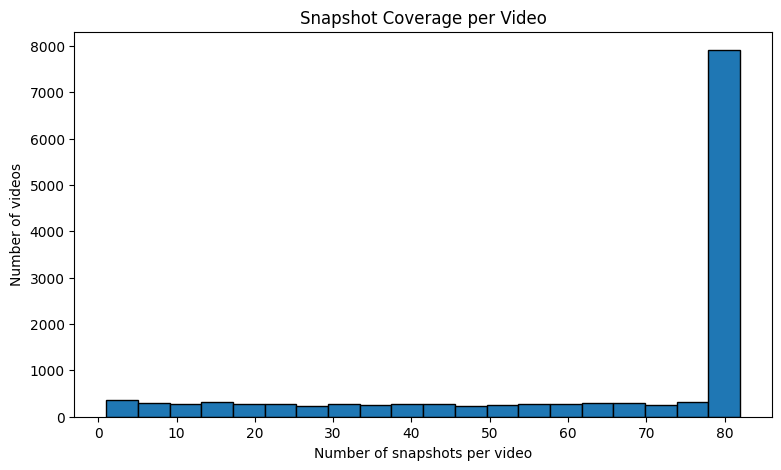

In [ ]:

# Number of observations collected per video
snapshots_per_video = (
    observation_df.groupby("video_id")
    .size()
    .rename("snapshot_count")
)

print(snapshots_per_video.describe())

# Distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    snapshots_per_video,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Number of snapshots per video")
plt.ylabel("Number of videos")
plt.title("Snapshot Coverage per Video")
plt.show()


In [ ]:

videos = video_df.copy()
obs = observation_df.copy()

videos["published_at"] = pd.to_datetime(
    videos["published_at"], utc=True
)

obs["observed_at"] = pd.to_datetime(
    obs["observed_at"], utc=True
)

# Earliest observation for each video
first_obs = (
    obs.groupby("video_id", as_index=False)
    ["observed_at"].min()
)

first_obs = first_obs.merge(
    videos[["video_id", "published_at"]].drop_duplicates("video_id"),
    on="video_id",
    how="left",
    validate="one_to_one"
)

# Age at first observation
first_obs["first_seen_age_hours"] = (
    first_obs["observed_at"] -
    first_obs["published_at"]
).dt.total_seconds() / 3600

display(first_obs["first_seen_age_hours"].describe())

print("Observed within 2 hours:",
      first_obs["first_seen_age_hours"].between(0, 2).sum())

print("Observed within 6 hours:",
      first_obs["first_seen_age_hours"].between(0, 6).sum())

print("First observed after 72 hours:",
      (first_obs["first_seen_age_hours"] > 72).sum())


count    13239.000000
mean         1.255727
std          0.654884
min          0.101810
25%          0.874998
50%          1.051664
75%          1.576361
max          3.003087
Name: first_seen_age_hours, dtype: float64

Observed within 2 hours: 11309
Observed within 6 hours: 13239
First observed after 72 hours: 0


In [ ]:
# Keep the latest country lookup if future datasets contain repeated checks.
countries_unique = (
    countries_df.sort_values("country_checked_at")
    .drop_duplicates("channel_id", keep="last")
)

country_counts = (
    countries_unique["channel_country"]
    .fillna("Unknown")
    .value_counts()
)

display(country_counts.head(20))

print("Channels in channels.csv:", channel_df["channel_id"].nunique())
print("Channels with a country check:", countries_unique["channel_id"].nunique())
print("Channels without a country record:", (~channel_df["channel_id"].isin(countries_unique["channel_id"])).sum())
print("US channels:", countries_unique["channel_country"].eq("US").sum())
print("Unknown checked countries:", countries_unique["channel_country"].isna().sum())


channel_country
IN         2495
Unknown    1857
US          821
ID          656
BR          474
VN          179
JP          177
KR          157
BD          156
TR          139
MX          109
ES           89
PK           75
DE           59
PL           49
GB           41
FR           41
AR           32
TH           31
CO           31
Name: count, dtype: int64

Channels in channels.csv: 8069
Channels with a country check: 8067
Channels without a country record: 2
US channels: 821
Unknown checked countries: 1857


In [ ]:
# Keep video_df unchanged so this cell is safe to rerun.
video_with_country_df = video_df.merge(
    countries_unique[["channel_id", "channel_country"]],
    on="channel_id",
    how="left",
    validate="many_to_one"
)

# Count videos by country
video_country_counts = (
    video_with_country_df["channel_country"]
    .fillna("Unknown")
    .value_counts()
)

display(video_country_counts.head(20))

us_channel_ids = set(
    countries_unique.loc[countries_unique["channel_country"].eq("US"), "channel_id"]
)
us_video_df = video_with_country_df[
    video_with_country_df["channel_id"].isin(us_channel_ids)
].copy()
us_channel_df = channel_df[channel_df["channel_id"].isin(us_channel_ids)].copy()
us_video_ids = set(us_video_df["video_id"])
us_observation_df = observation_df[
    observation_df["video_id"].isin(us_video_ids)
].copy()

print("US-associated videos:", us_video_df["video_id"].nunique())
print("US-associated channels:", us_channel_df["channel_id"].nunique())
print("US-associated observations:", len(us_observation_df))
print("Videos with unknown country:", video_with_country_df["channel_country"].isna().sum())


channel_country
IN         3913
Unknown    2698
US         1383
ID         1096
BR          895
VN          343
KR          338
TR          299
BD          265
JP          238
MX          205
PK          162
ES          149
DE          105
PL          104
AR           93
PE           64
GB           62
FR           60
CO           58
Name: count, dtype: int64

US-associated videos: 1383
US-associated channels: 821
US-associated observations: 88508
Videos with unknown country: 2698


## Early-feature and outcome eligibility

For each target age, select the observation closest to that age within the stated tolerance. A valid outcome must have a non-missing view count.

In [ ]:
def nearest_snapshot(observations, target_hour, tolerance_hours, required_columns=None):
    required_columns = required_columns or []
    candidates = observations.loc[
        observations["age_hours"].between(
            target_hour - tolerance_hours,
            target_hour + tolerance_hours,
        )
    ].copy()
    if required_columns:
        candidates = candidates.dropna(subset=required_columns)
    candidates["distance_hours"] = (candidates["age_hours"] - target_hour).abs()
    return (
        candidates.sort_values(["video_id", "distance_hours", "observed_at"])
        .drop_duplicates("video_id", keep="first")
        .drop(columns="distance_hours")
        .reset_index(drop=True)
    )

experiments = [
    {"feature_hour": 6, "feature_tolerance": 1, "outcome_hour": 48, "outcome_tolerance": 2},
    {"feature_hour": 6, "feature_tolerance": 1, "outcome_hour": 72, "outcome_tolerance": 2},
    {"feature_hour": 24, "feature_tolerance": 2, "outcome_hour": 72, "outcome_tolerance": 2},
]

eligibility_rows = []
for experiment in experiments:
    feature_snapshot = nearest_snapshot(
        observation_df,
        experiment["feature_hour"],
        experiment["feature_tolerance"],
        required_columns=["view_count"],
    )
    outcome_snapshot = nearest_snapshot(
        observation_df,
        experiment["outcome_hour"],
        experiment["outcome_tolerance"],
        required_columns=["view_count"],
    )
    eligible_ids = set(feature_snapshot["video_id"]) & set(outcome_snapshot["video_id"])
    eligibility_rows.append({
        **experiment,
        "feature_eligible_videos": feature_snapshot["video_id"].nunique(),
        "outcome_eligible_videos": outcome_snapshot["video_id"].nunique(),
        "both_eligible_videos": len(eligible_ids),
        "both_eligible_us_videos": len(eligible_ids & us_video_ids),
    })

eligibility_df = pd.DataFrame(eligibility_rows)
display(eligibility_df)
print("Data snapshot through:", observation_df["observed_at"].max())


,feature_hour,feature_tolerance,outcome_hour,outcome_tolerance,feature_eligible_videos,outcome_eligible_videos,both_eligible_videos,both_eligible_us_videos
0,6,1,48,2,12874,10084,10039,1077
1,6,1,72,2,12874,8481,8436,897
2,24,2,72,2,11693,8481,8480,902


Data snapshot through: 2026-10-20 17:53:38.240396+00:00


## Collection quality and observation coverage

These checks verify that the hourly collection produced usable longitudinal data. Count decreases are flagged for review because public metrics can occasionally be corrected by YouTube; they are not automatically treated as collection errors.

,rows,unique_videos,interval_hours,collection_duration_seconds
count,193.000000,193.000000,192.000000,193.000000
mean,4325.554404,4325.554404,1.011759,10.517060
std,1646.159226,1646.159226,0.216812,4.466116
min,96.000000,96.000000,0.105470,0.167245
25%,3347.000000,3347.000000,0.999431,7.934099
50%,5309.000000,5309.000000,1.000029,11.738098
75%,5456.000000,5456.000000,1.000641,13.024694
max,5549.000000,5549.000000,3.259194,30.962872


,metric,decrease_events,affected_videos,median_decrease,p95_decrease,maximum_decrease
0,view_count,18600,5308,7.0,128.05,13950.0
1,like_count,16614,6205,1.0,12.00,40311.0
2,comment_count,1524,1197,1.0,13.00,4278.0


,target_hour,tolerance_hours,eligible_videos,eligible_us_videos
0,6,1,12874,1345
1,24,2,11693,1252
2,48,2,10084,1082
3,72,2,8481,902
4,80,2,7970,832


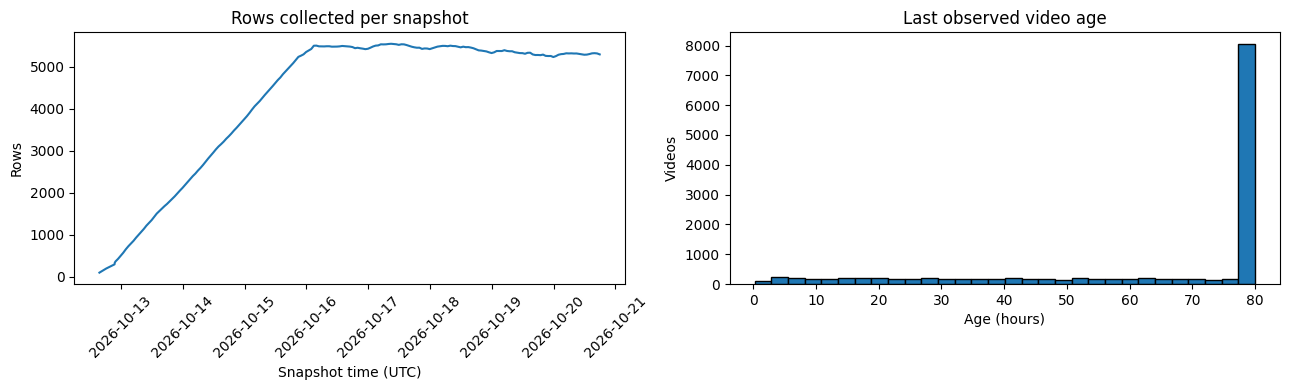

In [ ]:
import numpy as np

snapshot_quality_df = snapshot_manifest_df.sort_values("snapshot_started_at").copy()
snapshot_quality_df["interval_hours"] = (
    snapshot_quality_df["snapshot_started_at"].diff().dt.total_seconds() / 3600
)
snapshot_quality_df["collection_duration_seconds"] = (
    snapshot_quality_df["snapshot_finished_at"]
    - snapshot_quality_df["snapshot_started_at"]
).dt.total_seconds()

coverage_by_video_df = (
    observation_df.groupby("video_id", as_index=False)
    .agg(
        first_age_hours=("age_hours", "min"),
        last_age_hours=("age_hours", "max"),
        observation_count=("age_hours", "size"),
    )
)

sorted_observations = observation_df.sort_values(["video_id", "observed_at"])
decrease_rows = []
for metric in ["view_count", "like_count", "comment_count"]:
    differences = sorted_observations.groupby("video_id")[metric].diff()
    decreasing = differences.lt(0)
    decrease_magnitudes = -differences.loc[decreasing].dropna()
    decrease_rows.append({
        "metric": metric,
        "decrease_events": int(decreasing.sum()),
        "affected_videos": int(sorted_observations.loc[decreasing, "video_id"].nunique()),
        "median_decrease": decrease_magnitudes.median(),
        "p95_decrease": decrease_magnitudes.quantile(0.95),
        "maximum_decrease": decrease_magnitudes.max(),
    })
decrease_summary_df = pd.DataFrame(decrease_rows)

target_coverage_rows = []
for target_hour, tolerance in [(6, 1), (24, 2), (48, 2), (72, 2), (80, 2)]:
    selected = nearest_snapshot(
        observation_df, target_hour, tolerance, required_columns=["view_count"]
    )
    target_coverage_rows.append({
        "target_hour": target_hour,
        "tolerance_hours": tolerance,
        "eligible_videos": selected["video_id"].nunique(),
        "eligible_us_videos": selected["video_id"].isin(us_video_ids).sum(),
    })
target_coverage_df = pd.DataFrame(target_coverage_rows)

display(snapshot_quality_df[["rows", "unique_videos", "interval_hours", "collection_duration_seconds"]].describe())
display(decrease_summary_df)
display(target_coverage_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(snapshot_quality_df["snapshot_started_at"], snapshot_quality_df["rows"])
axes[0].set(title="Rows collected per snapshot", xlabel="Snapshot time (UTC)", ylabel="Rows")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(coverage_by_video_df["last_age_hours"], bins=30, edgecolor="black")
axes[1].set(title="Last observed video age", xlabel="Age (hours)", ylabel="Videos")
plt.tight_layout()
plt.show()


## Compare possible outcome horizons

The following comparison uses the nearest valid view count within ±2 hours of 24, 48, 72, and 80 hours. The thresholds below are exploratory and must later be estimated from training data only.

In [ ]:
from functools import reduce

HORIZON_TOLERANCES = {24: 2, 48: 2, 72: 2, 80: 2}
horizon_snapshots = {}
horizon_frames = []

for horizon, tolerance in HORIZON_TOLERANCES.items():
    selected = nearest_snapshot(
        observation_df, horizon, tolerance, required_columns=["view_count"]
    )
    horizon_snapshots[horizon] = selected
    horizon_frames.append(
        selected[["video_id", "age_hours", "view_count"]].rename(columns={
            "age_hours": f"age_{horizon}h",
            "view_count": f"views_{horizon}h",
        })
    )

outcome_panel_df = reduce(
    lambda left, right: left.merge(right, on="video_id", how="outer", validate="one_to_one"),
    horizon_frames,
)
view_columns = [f"views_{hour}h" for hour in HORIZON_TOLERANCES]

print("Available fixed-age outcomes:")
display(outcome_panel_df[view_columns].notna().sum().rename("videos").to_frame())
print("Spearman rank correlations:")
display(outcome_panel_df[view_columns].corr(method="spearman").round(3))

def compare_top_deciles(panel, earlier_hour, later_hour):
    earlier = f"views_{earlier_hour}h"
    later = f"views_{later_hour}h"
    common = panel.dropna(subset=[earlier, later]).copy()
    earlier_threshold = common[earlier].quantile(0.90)
    later_threshold = common[later].quantile(0.90)
    earlier_viral = common[earlier].ge(earlier_threshold)
    later_viral = common[later].ge(later_threshold)
    return {
        "comparison": f"{earlier_hour}h to {later_hour}h",
        "common_videos": len(common),
        "earlier_top_decile_retained_pct": round(
            100 * (earlier_viral & later_viral).sum() / earlier_viral.sum(), 2
        ),
        "overall_label_agreement_pct": round(100 * earlier_viral.eq(later_viral).mean(), 2),
    }

horizon_stability_df = pd.DataFrame([
    compare_top_deciles(outcome_panel_df, 24, 48),
    compare_top_deciles(outcome_panel_df, 48, 72),
    compare_top_deciles(outcome_panel_df, 72, 80),
])
display(horizon_stability_df)

growth_fraction_df = outcome_panel_df.dropna(
    subset=["views_24h", "views_48h", "views_72h"]
).copy()
positive_72h = growth_fraction_df["views_72h"].gt(0)
growth_fraction_df.loc[positive_72h, "share_72h_views_by_24h"] = (
    growth_fraction_df.loc[positive_72h, "views_24h"]
    / growth_fraction_df.loc[positive_72h, "views_72h"]
)
growth_fraction_df.loc[positive_72h, "share_72h_views_by_48h"] = (
    growth_fraction_df.loc[positive_72h, "views_48h"]
    / growth_fraction_df.loc[positive_72h, "views_72h"]
)
display(
    growth_fraction_df[["share_72h_views_by_24h", "share_72h_views_by_48h"]]
    .quantile([0.25, 0.50, 0.75])
    .round(3)
)


Available fixed-age outcomes:


,videos
views_24h,11693
views_48h,10084
views_72h,8481
views_80h,7970


Spearman rank correlations:


,views_24h,views_48h,views_72h,views_80h
views_24h,1.000,0.989,0.978,0.975
views_48h,0.989,1.000,0.997,0.995
views_72h,0.978,0.997,1.000,1.000
views_80h,0.975,0.995,1.000,1.000


,comparison,common_videos,earlier_top_decile_retained_pct,overall_label_agreement_pct
0,24h to 48h,10083,90.98,98.19
1,48h to 72h,8481,93.17,98.63
2,72h to 80h,7970,97.99,99.60


,share_72h_views_by_24h,share_72h_views_by_48h
0.25,0.585,0.851
0.50,0.737,0.923
0.75,0.860,0.969


## Provisional 72-hour popularity outcome

For EDA only, a video is labeled viral when its nearest valid 72-hour view count is at or above the 90th percentile. This is a popularity definition rather than evidence of network diffusion.

Eligible 72-hour outcomes: 8481
Exploratory 90th-percentile threshold: 739,556 views
Videos labeled viral: 849


,views_72h
0.00,327.0
0.25,30928.0
0.50,80255.0
0.75,255883.0
0.90,739556.0
0.95,1340674.0
0.99,4306081.0
1.00,23923610.0


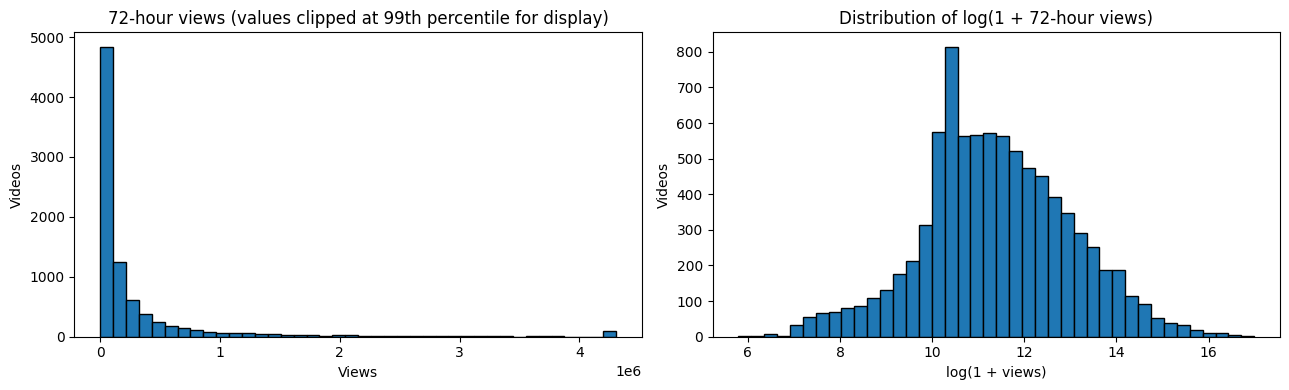

In [ ]:
outcome_72_df = horizon_snapshots[72].copy().rename(columns={
    "age_hours": "outcome_age_hours",
    "view_count": "views_72h",
    "like_count": "likes_72h",
    "comment_count": "comments_72h",
    "observed_at": "outcome_observed_at",
})
viral_threshold_72h = outcome_72_df["views_72h"].quantile(0.90)
outcome_72_df["is_viral_72h"] = outcome_72_df["views_72h"].ge(viral_threshold_72h)

print("Eligible 72-hour outcomes:", len(outcome_72_df))
print("Exploratory 90th-percentile threshold:", f"{viral_threshold_72h:,.0f} views")
print("Videos labeled viral:", outcome_72_df["is_viral_72h"].sum())
display(
    outcome_72_df["views_72h"]
    .quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .rename("views_72h")
    .to_frame()
)

plot_limit = outcome_72_df["views_72h"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(outcome_72_df["views_72h"].clip(upper=plot_limit), bins=40, edgecolor="black")
axes[0].set(
    title="72-hour views (values clipped at 99th percentile for display)",
    xlabel="Views", ylabel="Videos",
)
axes[1].hist(np.log1p(outcome_72_df["views_72h"]), bins=40, edgecolor="black")
axes[1].set(title="Distribution of log(1 + 72-hour views)", xlabel="log(1 + views)", ylabel="Videos")
plt.tight_layout()
plt.show()


## Growth trajectories: eventual viral versus nonviral videos

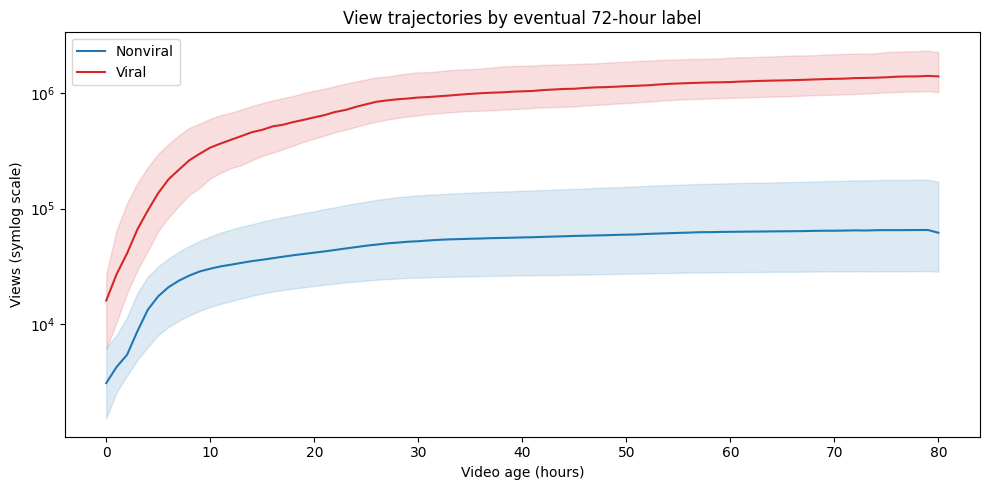

,age_hours,nonviral_median_views,viral_median_views,eligible_videos
0,1,4307.0,27455.5,7193
1,6,21008.0,178234.0,8436
2,12,32746.5,393942.0,8479
3,24,46450.0,756317.0,8480
4,48,58816.0,1120391.0,8481
5,72,65011.0,1340674.0,8481


In [ ]:
growth_df = observation_df[
    observation_df["video_id"].isin(outcome_72_df["video_id"])
    & observation_df["age_hours"].between(0, 80)
    & observation_df["view_count"].notna()
].merge(
    outcome_72_df[["video_id", "is_viral_72h"]],
    on="video_id",
    how="inner",
    validate="many_to_one",
)
growth_df["age_bin"] = growth_df["age_hours"].round().astype(int)

trajectory_df = (
    growth_df.groupby(["is_viral_72h", "age_bin"], as_index=False)
    .agg(
        median_views=("view_count", "median"),
        lower_quartile=("view_count", lambda values: values.quantile(0.25)),
        upper_quartile=("view_count", lambda values: values.quantile(0.75)),
        videos=("video_id", "nunique"),
    )
)

fig, ax = plt.subplots(figsize=(10, 5))
for viral_status, label, color in [(False, "Nonviral", "tab:blue"), (True, "Viral", "tab:red")]:
    subset = trajectory_df[trajectory_df["is_viral_72h"].eq(viral_status)]
    ax.plot(subset["age_bin"], subset["median_views"], label=label, color=color)
    ax.fill_between(
        subset["age_bin"].to_numpy(),
        subset["lower_quartile"].to_numpy(),
        subset["upper_quartile"].to_numpy(),
        color=color,
        alpha=0.15,
    )
ax.set_yscale("symlog", linthresh=1)
ax.set(title="View trajectories by eventual 72-hour label", xlabel="Video age (hours)", ylabel="Views (symlog scale)")
ax.legend()
plt.tight_layout()
plt.show()

trajectory_checkpoint_rows = []
for hour, tolerance in [(1, 1), (6, 1), (12, 1), (24, 2), (48, 2), (72, 2)]:
    checkpoint = nearest_snapshot(
        observation_df, hour, tolerance, required_columns=["view_count"]
    ).merge(
        outcome_72_df[["video_id", "is_viral_72h"]],
        on="video_id", how="inner", validate="one_to_one",
    )
    medians = checkpoint.groupby("is_viral_72h")["view_count"].median()
    trajectory_checkpoint_rows.append({
        "age_hours": hour,
        "nonviral_median_views": medians.get(False, np.nan),
        "viral_median_views": medians.get(True, np.nan),
        "eligible_videos": len(checkpoint),
    })
display(pd.DataFrame(trajectory_checkpoint_rows))


## Creator-size dependence

This section checks whether the provisional label mostly reflects established creator popularity.

,spearman_with_views_72h
subscriber_count,0.201
total_channel_views,0.274
total_channel_videos,-0.098


,subscriber_decile,videos,median_subscribers,median_views_72h,viral_rate
0,1,849,4130.0,35101.0,3.77
1,2,848,24050.0,55895.5,5.78
2,3,848,58100.0,63609.0,5.90
3,4,848,110000.0,72390.5,6.84
4,5,848,197500.0,85249.5,7.31
5,6,848,369000.0,88124.0,9.43
6,7,848,662000.0,101051.5,9.79
7,8,848,1450000.0,128936.0,15.68
8,9,848,3855000.0,110771.5,15.68
9,10,848,14350000.0,122047.0,19.93


Channels represented in videos.csv: 8069
Channels with multiple sampled videos: 2183
Share of videos from the 10 largest sampled channels: 3.38%
Channels with subscriber_count == 0: 0


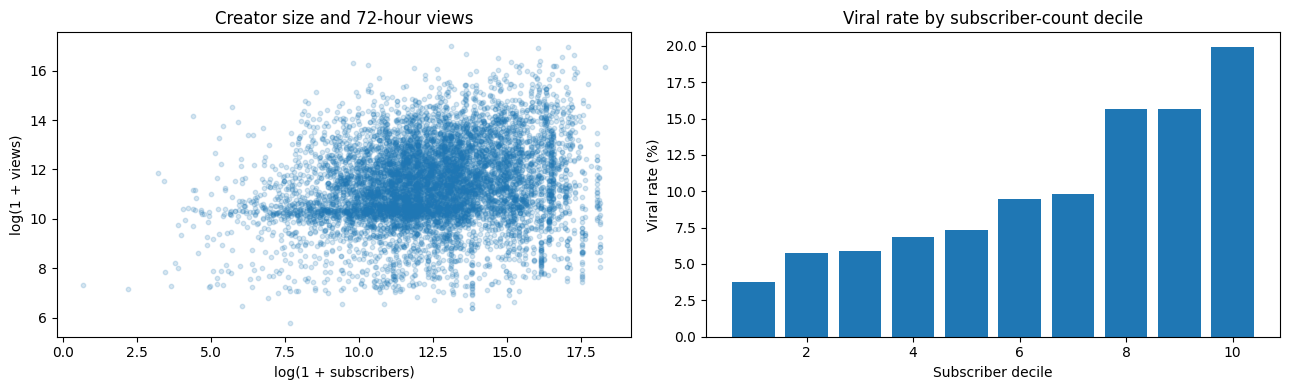

In [ ]:
outcome_analysis_df = (
    outcome_72_df.merge(
        video_with_country_df,
        on="video_id", how="left", validate="one_to_one",
    )
    .merge(
        channel_df[[
            "channel_id", "channel_created_at", "total_channel_views",
            "subscriber_count", "total_channel_videos",
        ]],
        on="channel_id", how="left", validate="many_to_one",
    )
)

creator_correlations = outcome_analysis_df[[
    "views_72h", "subscriber_count", "total_channel_views", "total_channel_videos"
]].corr(method="spearman")["views_72h"].drop("views_72h").rename("spearman_with_views_72h")
display(creator_correlations.to_frame().round(3))

outcome_analysis_df["subscriber_decile"] = (
    pd.qcut(
        outcome_analysis_df["subscriber_count"].rank(method="first"),
        q=10, labels=False,
    ) + 1
)
subscriber_decile_df = (
    outcome_analysis_df.groupby("subscriber_decile", as_index=False)
    .agg(
        videos=("video_id", "size"),
        median_subscribers=("subscriber_count", "median"),
        median_views_72h=("views_72h", "median"),
        viral_rate=("is_viral_72h", "mean"),
    )
)
subscriber_decile_df["viral_rate"] *= 100
display(subscriber_decile_df.round(2))

videos_per_channel = video_df.groupby("channel_id")["video_id"].nunique().sort_values(ascending=False)
print("Channels represented in videos.csv:", videos_per_channel.size)
print("Channels with multiple sampled videos:", videos_per_channel.gt(1).sum())
print("Share of videos from the 10 largest sampled channels:", f"{100 * videos_per_channel.head(10).sum() / len(video_df):.2f}%")
print("Channels with subscriber_count == 0:", channel_df["subscriber_count"].eq(0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(
    np.log1p(outcome_analysis_df["subscriber_count"]),
    np.log1p(outcome_analysis_df["views_72h"]),
    alpha=0.18, s=10,
)
axes[0].set(title="Creator size and 72-hour views", xlabel="log(1 + subscribers)", ylabel="log(1 + views)")
axes[1].bar(subscriber_decile_df["subscriber_decile"], subscriber_decile_df["viral_rate"])
axes[1].set(title="Viral rate by subscriber-count decile", xlabel="Subscriber decile", ylabel="Viral rate (%)")
plt.tight_layout()
plt.show()


## Content metadata associations

,duration_bin,videos,median_views_72h,viral_rate
0,"(-0.001, 15.0]",691,113760.0,15.05
1,"(15.0, 30.0]",2517,74652.0,10.01
2,"(30.0, 60.0]",3270,73525.5,9.39
3,"(60.0, 90.0]",1030,83752.0,8.54
4,"(90.0, 120.0]",414,79561.0,8.70
5,"(120.0, 180.0]",559,122366.0,11.09


,duration_seconds,title_length,title_word_count,description_length,hashtag_count,tag_count
is_viral_72h,,,,,,
Nonviral,39.0,62.0,9.0,67.0,5.0,0.0
Viral,37.0,60.0,9.0,51.0,4.0,0.0


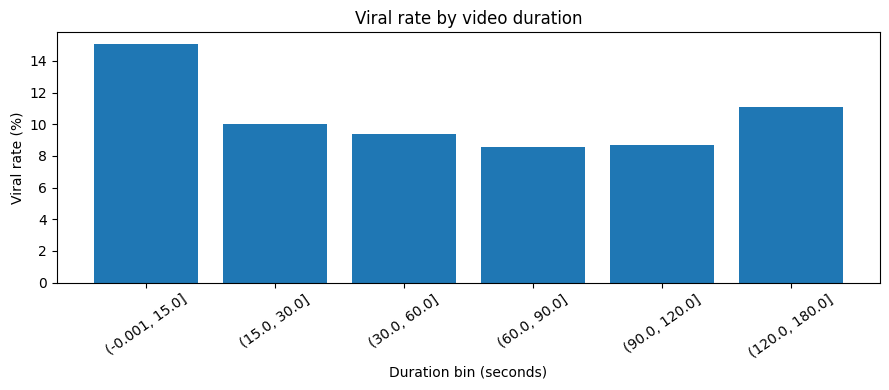

In [ ]:
import ast

def tag_count(value):
    if pd.isna(value):
        return 0
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
    except (SyntaxError, ValueError):
        return np.nan
    return len(parsed) if isinstance(parsed, (list, tuple, set)) else np.nan

outcome_analysis_df["title_length"] = outcome_analysis_df["title"].str.len()
outcome_analysis_df["title_word_count"] = outcome_analysis_df["title"].str.split().str.len()
outcome_analysis_df["description_present"] = outcome_analysis_df["description"].notna()
outcome_analysis_df["description_length"] = outcome_analysis_df["description"].fillna("").str.len()
combined_text = (
    outcome_analysis_df["title"].fillna("") + " "
    + outcome_analysis_df["description"].fillna("")
)
outcome_analysis_df["hashtag_count"] = combined_text.str.count(r"#\w+")
outcome_analysis_df["tag_count"] = outcome_analysis_df["tags"].map(tag_count)

duration_bins = [0, 15, 30, 60, 90, 120, 180]
outcome_analysis_df["duration_bin"] = pd.cut(
    outcome_analysis_df["duration_seconds"],
    bins=duration_bins,
    include_lowest=True,
)
duration_summary_df = (
    outcome_analysis_df.groupby("duration_bin", observed=True, as_index=False)
    .agg(
        videos=("video_id", "size"),
        median_views_72h=("views_72h", "median"),
        viral_rate=("is_viral_72h", "mean"),
    )
)
duration_summary_df["viral_rate"] *= 100
display(duration_summary_df.round(2))

content_feature_summary_df = (
    outcome_analysis_df.groupby("is_viral_72h")[[
        "duration_seconds", "title_length", "title_word_count",
        "description_length", "hashtag_count", "tag_count",
    ]]
    .median()
    .rename(index={False: "Nonviral", True: "Viral"})
)
display(content_feature_summary_df.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(duration_summary_df["duration_bin"].astype(str), duration_summary_df["viral_rate"])
ax.set(title="Viral rate by video duration", xlabel="Duration bin (seconds)", ylabel="Viral rate (%)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


## Publication timing and country comparisons

Publication times are UTC. Channel country is self-reported channel metadata, not verified upload location or audience location.

,publish_day_utc,videos,median_views_72h,viral_rate
1,Monday,536,77440.5,11.94
4,Tuesday,1603,75494.0,9.73
5,Wednesday,1637,77143.0,10.32
3,Thursday,1706,72506.0,9.26
0,Friday,1646,84003.0,9.17
2,Saturday,1353,92289.0,11.16


,country_group,videos,channels,median_subscribers,median_views_72h,viral_rate
0,Other,5870,3850,348000.0,76027.0,8.84
1,US,902,581,217000.0,105583.5,13.75
2,Unknown,1709,1297,132000.0,82591.0,12.05


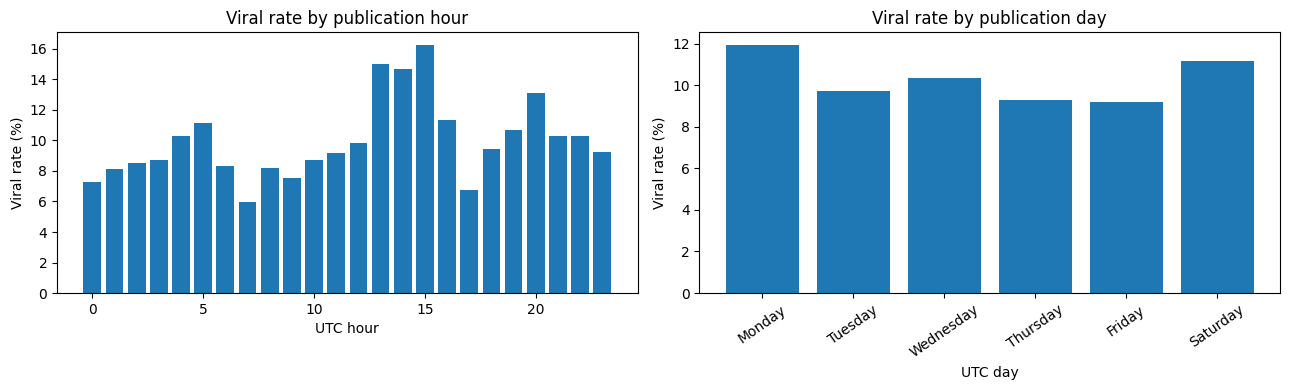

In [ ]:
outcome_analysis_df["publish_hour_utc"] = outcome_analysis_df["published_at"].dt.hour
outcome_analysis_df["publish_day_utc"] = outcome_analysis_df["published_at"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

hour_summary_df = (
    outcome_analysis_df.groupby("publish_hour_utc", as_index=False)
    .agg(videos=("video_id", "size"), median_views_72h=("views_72h", "median"), viral_rate=("is_viral_72h", "mean"))
)
hour_summary_df["viral_rate"] *= 100
day_summary_df = (
    outcome_analysis_df.groupby("publish_day_utc", as_index=False)
    .agg(videos=("video_id", "size"), median_views_72h=("views_72h", "median"), viral_rate=("is_viral_72h", "mean"))
)
day_summary_df["publish_day_utc"] = pd.Categorical(
    day_summary_df["publish_day_utc"], categories=day_order, ordered=True
)
day_summary_df = day_summary_df.sort_values("publish_day_utc")
day_summary_df["viral_rate"] *= 100

outcome_analysis_df["country_group"] = np.where(
    outcome_analysis_df["channel_country"].eq("US"), "US",
    np.where(outcome_analysis_df["channel_country"].isna(), "Unknown", "Other"),
)
country_comparison_df = (
    outcome_analysis_df.groupby("country_group", as_index=False)
    .agg(
        videos=("video_id", "size"),
        channels=("channel_id", "nunique"),
        median_subscribers=("subscriber_count", "median"),
        median_views_72h=("views_72h", "median"),
        viral_rate=("is_viral_72h", "mean"),
    )
)
country_comparison_df["viral_rate"] *= 100

display(day_summary_df.round(2))
display(country_comparison_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(hour_summary_df["publish_hour_utc"], hour_summary_df["viral_rate"])
axes[0].set(title="Viral rate by publication hour", xlabel="UTC hour", ylabel="Viral rate (%)")
axes[1].bar(day_summary_df["publish_day_utc"].astype(str), day_summary_df["viral_rate"])
axes[1].set(title="Viral rate by publication day", xlabel="UTC day", ylabel="Viral rate (%)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


## Six-hour engagement and missingness

These are descriptive associations with the later label. Only six-hour information may be used in a six-hour prediction model.

In [ ]:
feature_6h_df = nearest_snapshot(
    observation_df, 6, 1, required_columns=["view_count"]
).rename(columns={
    "observed_at": "feature_observed_at_6h",
    "age_hours": "feature_age_hours_6h",
    "view_count": "views_6h",
    "like_count": "likes_6h",
    "comment_count": "comments_6h",
})

eda_model_df = outcome_analysis_df.merge(
    feature_6h_df[[
        "video_id", "feature_observed_at_6h", "feature_age_hours_6h",
        "views_6h", "likes_6h", "comments_6h",
    ]],
    on="video_id", how="inner", validate="one_to_one",
)
eda_model_df["likes_6h_missing"] = eda_model_df["likes_6h"].isna()
eda_model_df["comments_6h_missing"] = eda_model_df["comments_6h"].isna()
eda_model_df["smoothed_like_rate_6h"] = (
    (eda_model_df["likes_6h"] + 1) / (eda_model_df["views_6h"] + 100)
)
eda_model_df["smoothed_comment_rate_6h"] = (
    (eda_model_df["comments_6h"] + 1) / (eda_model_df["views_6h"] + 100)
)

missingness_by_label_df = (
    eda_model_df.groupby("is_viral_72h")[["likes_6h_missing", "comments_6h_missing"]]
    .mean()
    .mul(100)
    .rename(index={False: "Nonviral", True: "Viral"})
)
display(missingness_by_label_df.round(2))

early_signal_df = (
    eda_model_df.groupby("is_viral_72h")[[
        "views_6h", "likes_6h", "comments_6h",
        "smoothed_like_rate_6h", "smoothed_comment_rate_6h",
    ]]
    .median()
    .rename(index={False: "Nonviral", True: "Viral"})
)
display(early_signal_df.round(4))

correlation_frame = pd.DataFrame({
    "log_views_72h": np.log1p(eda_model_df["views_72h"]),
    "log_views_6h": np.log1p(eda_model_df["views_6h"]),
    "log_likes_6h": np.log1p(eda_model_df["likes_6h"]),
    "log_comments_6h": np.log1p(eda_model_df["comments_6h"]),
    "smoothed_like_rate_6h": eda_model_df["smoothed_like_rate_6h"],
    "smoothed_comment_rate_6h": eda_model_df["smoothed_comment_rate_6h"],
})
display(correlation_frame.corr(method="spearman")[["log_views_72h"]].round(3))
print("Videos with both a valid 6-hour feature snapshot and 72-hour outcome:", len(eda_model_df))


,likes_6h_missing,comments_6h_missing
is_viral_72h,,
Nonviral,12.05,0.74
Viral,12.49,0.83


,views_6h,likes_6h,comments_6h,smoothed_like_rate_6h,smoothed_comment_rate_6h
is_viral_72h,,,,,
Nonviral,21008.0,419.0,4.0,0.0226,0.0003
Viral,178234.0,4075.5,19.5,0.0253,0.0001


,log_views_72h
log_views_72h,1.000
log_views_6h,0.842
log_likes_6h,0.772
log_comments_6h,0.421
smoothed_like_rate_6h,0.129
smoothed_comment_rate_6h,-0.235


Videos with both a valid 6-hour feature snapshot and 72-hour outcome: 8436


## Interpretation guardrails

- Report the data snapshot timestamp with every result.
- Treat the top-decile cutoff in this notebook as exploratory; estimate production thresholds from training data only.
- Do not interpret observed associations as causal effects.
- Keep missing engagement indicators because likes and comments may be unavailable for systematic reasons.
- Use channel-grouped and chronological validation later to avoid creator and future-information leakage.
- Reassess the US-only scope because the 72-hour US subset contains far fewer positive cases than the worldwide sample.